# Assignment 2A : Building Models for Building Energy Prediction

## Table of Contents
*  
    * [Part 1 : Data Loading, Transformation and Exploration](#part-1)
    * [Part 2 : Feature extraction and ML training](#part-2)
    * [Part 3 : Hyperparameter Tuning and Model Optimisation](#part-3)
    * [Part 4 : Data Ethics, Privacy, and Security](#part-4)


## Group G:
1. [teammate]
2. Akhmad Fauzi Nurulhamzah

# Part 1: Data Loading, Transformation and Exploration <a class="anchor" name="part-1"></a>
## 1.1 Data Loading
In this section, you must load the given datasets into PySpark DataFrames and use DataFrame functions to process the data. For plotting, various visualisation packages can be used, but please ensure that you have included instructions to install the additional packages and that the installation will be successful in the provided Docker container (in case your marker needs to clear the notebook and rerun it).

### 1.1.1 Data Loading <a class="anchor" name="1.1"></a>
#### 1.1.1 Write the code to create a SparkSession. 
For creating the SparkSession, you need to use a SparkConf object to configure the Spark app with a proper application name, to ensure the maximum partition size does not exceed 32MB, and to run locally with all CPU cores on your machine

In [1]:
# ==============================
# 1.1.1 Create SparkSession for Building Energy Prediction
# ==============================

from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession

# local[*]: run Spark locally using all available CPU cores
master = "local[*]"
app_name = "ITI5202_A2A_Building_Energy_Prediction"

# Cap each partition at 32MB when reading files, as required by the assignment
max_partition_bytes = 32 * 1024 * 1024  # 32MB in bytes

spark_conf = SparkConf() \
    .setMaster(master) \
    .setAppName(app_name) \
    .set("spark.sql.files.maxPartitionBytes", max_partition_bytes)

spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')

# Verify configuration
print("App Name:", spark.conf.get("spark.app.name"))
print("Master:", sc.master)
print("Max Partition Bytes:", spark.conf.get("spark.sql.files.maxPartitionBytes"))

App Name: ITI5202_A2A_Building_Energy_Prediction
Master: local[*]
Max Partition Bytes: 33554432


Spark splits each input file into partitions and runs one task per partition, spreading those tasks across the cores that `local[*]` makes available. Capping `spark.sql.files.maxPartitionBytes` at 32MB bounds how much data any single task has to read, so a large file such as `meters.csv` is divided into many small units of work instead of a few large ones, and the cores finish at roughly the same time rather than waiting on one long task.

Taniar et al. define skew as "the nonuniformity of workload distribution among processing elements" and treat it as one of the main problems in parallel processing (2008, section 2.3, p. 39). Bounding the partition size is one of the levers that limits it, which is why the configuration is set this way rather than left at its default.

#### 1.1.2 Write code to define the schemas for the datasets, following the data types suggested in the metadata file. 

In [2]:
# ==============================
# 1.1.2 Define Schemas for the Datasets
# ==============================

from pyspark.sql.types import (
    StructType, StructField,
    IntegerType, StringType, TimestampType, DecimalType, DoubleType  
)

# Meter table schema (energy consumption readings)
meter_schema = StructType([
    StructField("building_id", IntegerType(), True),
    StructField("meter_type", StringType(), True),      # 'e', 'c', 's', 'h'
    StructField("ts", TimestampType(), True),
    StructField("value", DecimalType(10, 2), True), 
    StructField("row_id", IntegerType(), True)
])

# Buildings table schema (static building metadata)
building_schema = StructType([
    StructField("site_id", IntegerType(), True),
    StructField("building_id", IntegerType(), True),
    StructField("primary_use", StringType(), True),
    StructField("square_feet", IntegerType(), True),
    StructField("floor_count", IntegerType(), True),
    StructField("row_id", IntegerType(), True),
    StructField("year_built", IntegerType(), True),
    StructField("latent_y", DecimalType(10, 4), True),
    StructField("latent_s", DecimalType(10, 4), True),
    StructField("latent_r", DecimalType(10, 4), True)
])

# Weather table schema (per-site weather readings)
weather_schema = StructType([
    StructField("site_id",            IntegerType(),  True),
    StructField("timestamp",          TimestampType(), True),
    StructField("air_temperature",    DecimalType(6, 2), True),
    StructField("cloud_coverage",     DoubleType(), True),       # because values are decimal-formatted
    StructField("dew_temperature",    DecimalType(6, 2), True),
    StructField("sea_level_pressure", DecimalType(8, 2), True), 
    StructField("wind_direction",     DoubleType(), True),       # values are decimal-formatted
    StructField("wind_speed",         DecimalType(6, 2), True)
])

#### 1.1.3 Using your schemas, load the CSV files into separate data frames. Print the schemas of all data frames. 

In [3]:
# ==============================
# 1.1.3 Load Datasets Using Defined Schemas
# ==============================

# Load meter data
meter_df = spark.read.csv(
    "dataset/meters.csv",
    header=True,
    schema=meter_schema
)

# Load building information
building_df = spark.read.csv(
    "dataset/building_information.csv",
    header=True,
    schema=building_schema
)

# Load weather data
weather_df = spark.read.csv(
    "dataset/weather.csv",
    header=True,
    schema=weather_schema
)

# Display sample rows to verify the data loaded correctly
meter_df.show(5)
building_df.show(5)
weather_df.show(5)

# Print schemas to verify they match the metadata
meter_df.printSchema()
building_df.printSchema()
weather_df.printSchema()

+-----------+----------+-------------------+------+------+
|building_id|meter_type|                 ts| value|row_id|
+-----------+----------+-------------------+------+------+
|        161|         c|2022-01-01 00:00:00|  0.00|     1|
|        162|         c|2022-01-01 00:00:00|  0.00|     2|
|        166|         c|2022-01-01 00:00:00|209.89|     4|
|        167|         c|2022-01-01 00:00:00|  0.00|     5|
|        168|         c|2022-01-01 00:00:00| 51.56|     6|
+-----------+----------+-------------------+------+------+
only showing top 5 rows
+-------+-----------+-------------+-----------+-----------+------+----------+--------+--------+--------+
|site_id|building_id|  primary_use|square_feet|floor_count|row_id|year_built|latent_y|latent_s|latent_r|
+-------+-----------+-------------+-----------+-----------+------+----------+--------+--------+--------+
|      2|        165|    Warehouse|       3877|          1|   166|      1982| 18.0000|  3.5885|  3.0000|
|      2|        229|    

### 1.2 Data Transformation to Create Features <a class="anchor" name="1.2"></a>
In this section, we primarily have three tasks:
1.2.1 The dataset includes sensors with hourly energy measurements. However, as a grid operator, we don’t need this level of granularity and lowering it can reduce the amount of data we need to process. For each building, we will aggregate the metered energy consumption in 6-hour intervals (0:00-5:59, 6:00-11:59, 12:00-17:59, 18:00-23:59). This will be our target (label) column for this prediction. Perform the aggregation for each building.


Each row in `meters.csv` is one reading from one meter at one hour, so `(building_id, meter_type, ts)` should identify a row uniquely. However the data not showing that. Some keys appear more than once, and in most of those cases the two rows carry different values. The counts are printed below.

This matters for the label. The 6-hour aggregation sums `value`, so two rows sharing a key are added together, and `energy_consumption` ends up higher than the meter ever reported for that hour.

Nothing in the data says which reading is the right one. There is no correction flag, and a higher `row_id` does not mean a later record. Each key is **therefore reduced to one value by averaging before the sum is taken**. The average sits between the two recorded readings, and it uses the same approach as the mean imputation applied to the weather data in 1.2.2. Dropping one row from each pair would mean picking at random.

In [4]:
# ==============================
# 1.2.1 Aggregate Meter Readings into 6-Hour Intervals (Label Column)
# ==============================

from pyspark.sql import functions as F

# Profile the duplicate keys first, so the fix below rests on measured numbers
dup_groups = meter_df.groupBy("building_id", "meter_type", "ts").agg(
    F.count("*").alias("n_rows"),
    # A key's duplicated rows disagree whenever their max and min differ. This is much
    # cheaper than countDistinct, which would have to track every distinct value.
    (F.max("value") != F.min("value")).alias("values_disagree")
).filter(F.col("n_rows") > 1).persist()

n_groups = dup_groups.count()
n_rows_involved = dup_groups.agg(F.sum("n_rows")).first()[0]
n_conflicting = dup_groups.filter(F.col("values_disagree")).count()

print("Duplicate (building_id, meter_type, ts) groups:", n_groups)
print("Rows involved:", n_rows_involved)
print("Groups whose duplicated rows disagree on value:", n_conflicting,
      f"({100 * n_conflicting / n_groups:.1f}%)")
dup_groups.unpersist()

# Deduplicate (building_id, meter_type, ts) keys via mean -- see markdown note above
meter_dedup_df = meter_df.groupBy("building_id", "meter_type", "ts").agg(
    F.mean("value").alias("value")
)

# Coverage check. The specification notes that meter readings can go missing when a sensor
# or the network fails. Those losses appear as absent rows rather than nulls, so they are
# measured here as readings per meter against the 8,760 hours in a non-leap year.
readings_per_meter = meter_dedup_df.groupBy("building_id", "meter_type").agg(
    F.count("*").alias("n_readings")
)
cov = readings_per_meter.select(
    F.count("*").alias("series"),
    F.min("n_readings").alias("min_readings"),
    F.max("n_readings").alias("max_readings"),
    F.round(F.avg("n_readings")).alias("mean_readings"),
    F.count(F.when(F.col("n_readings") < 8760, True)).alias("incomplete")
).first()

print("Meter series (building, meter_type):", cov["series"])
print("Readings per series: min", cov["min_readings"],
      "| max", cov["max_readings"], "| mean", cov["mean_readings"])
print("Series short of the full 8,760 hours:", cov["incomplete"])

# Extract the calendar date from the timestamp
meter_interval_df = meter_dedup_df.withColumn(
    "date", F.to_date("ts")
).withColumn(
    # Determine the 6-hour bucket start hour (0, 6, 12, or 18)
    "interval_start_hour", (F.hour("ts") / 6).cast("int") * 6
).withColumn(
    # Rebuild a proper timestamp marking the start of the interval
    "interval_start",
    F.to_timestamp(
        F.concat_ws(" ", F.col("date").cast("string"),
                    F.lpad(F.col("interval_start_hour").cast("string"), 2, "0")),
        "yyyy-MM-dd HH"
    )
)

# Sum all meter types (e/c/s/h) together per building per 6-hour interval,
# as the aggregated value of the 4 meters is the target variable
label_df = meter_interval_df.groupBy("building_id", "interval_start").agg(
    F.sum("value").alias("energy_consumption")
)

# Display sample rows to verify the aggregation
label_df.orderBy("building_id", "interval_start").show(10)

# Print schema to verify the resulting structure
label_df.printSchema()

Duplicate (building_id, meter_type, ts) groups: 35516
Rows involved: 71032
Groups whose duplicated rows disagree on value: 30136 (84.9%)
Meter series (building, meter_type): 1627
Readings per series: min 479 | max 8759 | mean 8475.0
Series short of the full 8,760 hours: 1627
+-----------+-------------------+------------------+
|building_id|     interval_start|energy_consumption|
+-----------+-------------------+------------------+
|          0|2022-01-01 00:00:00|          0.000000|
|          0|2022-01-01 06:00:00|          0.000000|
|          0|2022-01-01 12:00:00|          0.000000|
|          0|2022-01-01 18:00:00|          0.000000|
|          0|2022-01-02 00:00:00|          0.000000|
|          0|2022-01-02 06:00:00|          0.000000|
|          0|2022-01-02 12:00:00|          0.000000|
|          0|2022-01-02 18:00:00|          0.000000|
|          0|2022-01-03 00:00:00|          0.000000|
|          0|2022-01-03 06:00:00|          0.000000|
+-----------+-------------------+--

**Incomplete meter coverage.** The counts above show how many hourly readings each `(building_id, meter_type)` series actually carries against the 8,760 hours in the year. Many series fall well short, which is the sensor and network loss the specification refers to. The gaps are absent rows, not nulls, so no imputation step would find them.

This matters for the label because the 6-hour aggregation sums whatever readings exist. A block holding two readings is summed the same way as one holding six, so buckets over a gap understate consumption, and the model cannot tell a quiet period from a period that went unrecorded.

We aggregate over the available readings and leave the gaps in place. Filling them would mean inventing consumption for hours nobody measured, and a meter being offline says nothing about whether the building was drawing power. Rescaling each bucket by its reading count was the other option considered, but that assumes consumption is even across the block, which is exactly the assumption the 6-hour split exists to avoid. The limitation is therefore accepted and recorded rather than papered over: some label values are low because the meter was silent, and that noise sets a floor on the accuracy any model here can reach.

In **the weather dataset, there are some missing values (null or empty strings)**. It may lower the quality of our model. Imputation is a way to deal with those missing values. Imputation is the process of replacing missing values in a dataset with substituted, or "imputed," values. It's a way to handle gaps in your data so that you can still analyse it effectively without having to delete incomplete records.  
1.2.2 Refer to the Spark MLLib imputation API and fill in the missing values in the weather dataset. You can use mean values as the strategy.  https://spark.apache.org/docs/3.5.5/api/python/reference/api/pyspark.ml.feature.Imputer.html

+-------+----+-----------------+-------------------+
|site_id|rows|cloud_missing_pct|winddir_missing_pct|
+-------+----+-----------------+-------------------+
|      0|8784|             43.6|                2.8|
|      1|8763|             80.6|                0.0|
|      2|8783|             26.8|                6.7|
|      3|8780|             41.5|                1.7|
|      4|8783|             48.2|                1.2|
|      5|8755|             68.9|                3.4|
|      6|8782|             34.1|                8.9|
|      7|8614|            100.0|                0.0|
|      8|8784|             43.6|                2.8|
|      9|8780|             39.4|               29.1|
|     10|8782|             27.9|                6.1|
|     11|8614|            100.0|                0.0|
|     12|8755|              0.7|                0.0|
|     13|8783|             48.9|                2.5|
|     14|8777|             37.7|                3.3|
|     15|8454|             52.0|              

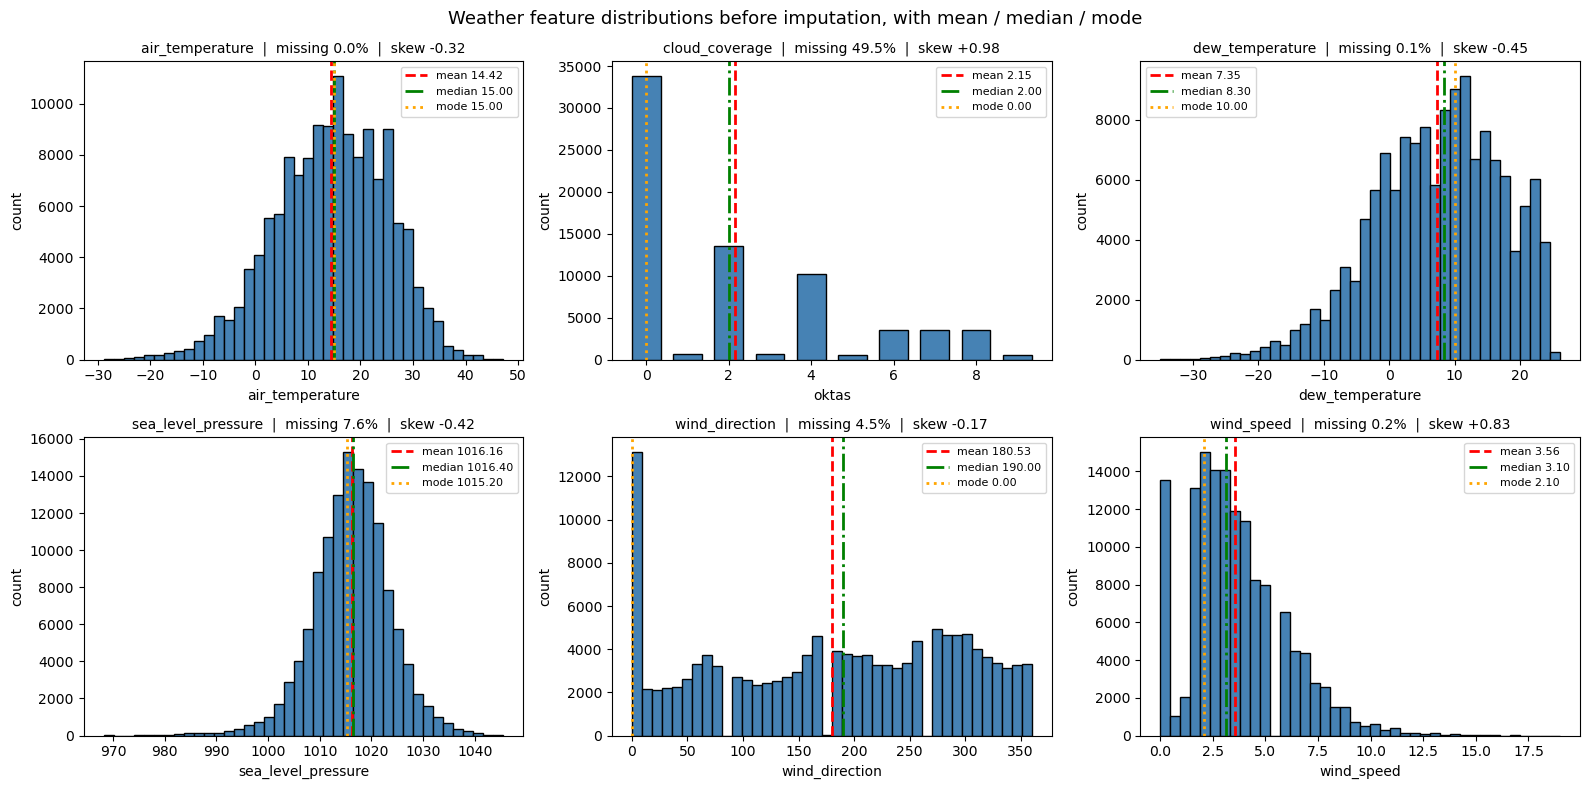

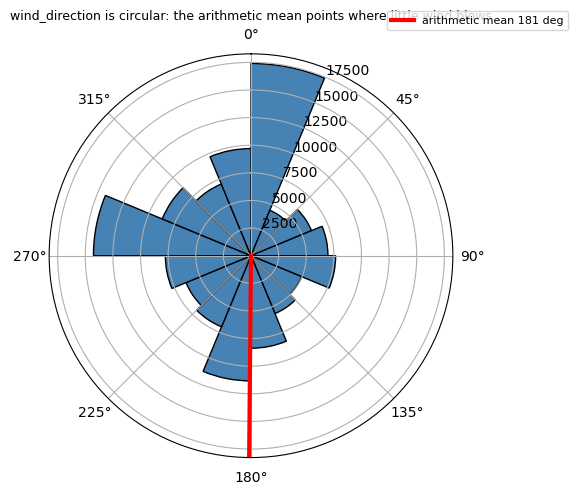

In [5]:
# ==============================
# 1.2.2 (a) Profile the Weather Distributions Before Choosing an Imputation Strategy
# ==============================

import matplotlib.pyplot as plt
import numpy as np

numeric_cols = ["air_temperature", "cloud_coverage", "dew_temperature",
                "sea_level_pressure", "wind_direction", "wind_speed"]

# The weather table is small (139,773 rows), so it is safe to bring to Pandas for plotting
weather_pd = weather_df.select(
    [F.col(c).cast("double").alias(c) for c in numeric_cols]
).toPandas()

# Missingness is not spread evenly across sites, so profile it per site as well.
# A full non-leap year of hourly readings is 8,760 rows per site.
weather_df.groupBy("site_id").agg(
    F.count("*").alias("rows"),
    F.round(100 * F.avg(F.col("cloud_coverage").isNull().cast("double")), 1).alias("cloud_missing_pct"),
    F.round(100 * F.avg(F.col("wind_direction").isNull().cast("double")), 1).alias("winddir_missing_pct")
).orderBy("site_id").show(16)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.ravel(), numeric_cols):
    s = weather_pd[col].dropna()
    mean_v, median_v, mode_v = s.mean(), s.median(), s.mode().iloc[0]

    if col == "cloud_coverage":
        # Ordinal okta scale, so a bar chart of the discrete levels is clearer than a histogram
        counts = s.value_counts().sort_index()
        ax.bar(counts.index, counts.values, width=0.7, color="steelblue", edgecolor="black")
        ax.set_xlabel("oktas")
    else:
        ax.hist(s, bins=40, color="steelblue", edgecolor="black")
        ax.set_xlabel(col)

    ax.axvline(mean_v,   color="red",    ls="--", lw=2, label=f"mean {mean_v:.2f}")
    ax.axvline(median_v, color="green",  ls="-.", lw=2, label=f"median {median_v:.2f}")
    ax.axvline(mode_v,   color="orange", ls=":",  lw=2, label=f"mode {mode_v:.2f}")

    title = f"{col}  |  missing {100 * weather_pd[col].isna().mean():.1f}%  |  skew {s.skew():+.2f}"
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("count")
    ax.legend(fontsize=8)

plt.suptitle("Weather feature distributions before imputation, with mean / median / mode", fontsize=13)
plt.tight_layout()
plt.show()

# --- wind_direction is circular, so an arithmetic mean is not a real direction ---
wd = weather_pd["wind_direction"].dropna()
counts, edges = np.histogram(wd, bins=np.arange(0, 361, 22.5))

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="polar")
ax.bar(np.deg2rad(edges[:-1] + 11.25), counts,
       width=np.deg2rad(22.5), color="steelblue", edgecolor="black")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.axvline(np.deg2rad(wd.mean()), color="red", lw=3,
           label=f"arithmetic mean {wd.mean():.0f} deg")
ax.set_title("wind_direction is circular: the arithmetic mean points where little wind blows", fontsize=9)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.12), fontsize=8)
plt.tight_layout()
plt.show()


**Choosing an imputation strategy per column.** As the Assignment Specification guidline, we use the Spark MLlib `Imputer`. However, rather than applying one strategy blindly (mean), we profiled each column first and picked the statistic that actually fits its distribution. `Imputer` applies a single strategy per instance, so we simply group the columns and fit one `Imputer` per strategy.

| Column | Missing | Shape | Strategy | Reason |
|---|---:|---|---|---|
| `air_temperature` | 0.0% | near-symmetric (skew -0.32) | `mean` | mean, median and mode all coincide |
| `dew_temperature` | 0.1% | mild left skew (-0.45) | `mean` | negligible missingness, symmetric enough |
| `sea_level_pressure` | 7.6% | near-symmetric (-0.42) | `mean` | mean 1016.16 vs median 1016.40, a 0.02% difference |
| `wind_speed` | 0.2% | right-skewed (+0.83) | `median` | the mean is dragged up by the long upper tail |
| `cloud_coverage` | 49.5% | ordinal, 0-8 oktas | `median` | the mean (2.15) is not a valid okta; the median (2.0) is |
| `wind_direction` | 4.5% | circular, 0-360 deg | `mode` | on a compass the mean is meaningless (see polar plot); the mode at least returns a direction that was actually observed |

Mean is kept wherever the distribution genuinely supports it, which is three of the six columns. The other three use median or mode instead, because the plots above show what the mean would produce there: a value outside the measurement scale, a figure inflated by a long upper tail, and a compass direction that no observation ever recorded.

In [6]:
# ==============================
# 1.2.2 Impute Missing Values in Weather Dataset
# ==============================

from pyspark.sql import functions as F
from pyspark.ml.feature import Imputer
from pyspark.sql.types import DoubleType

# Columns that may contain missing values (per assignment spec):
# cloud_coverage, sea_level_pressure, wind_direction
numeric_cols = ["air_temperature", "cloud_coverage", "dew_temperature",
                 "sea_level_pressure", "wind_direction", "wind_speed"]

total_rows = weather_df.count()

# Count how many nulls each column has
null_counts = weather_df.select(
    [F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in numeric_cols]
).collect()[0].asDict()

# Separate columns into two groups:
# - imputable_cols: have SOME missing values, so Imputer can compute a valid statistic
# - fully_empty_cols: have EVERY row missing, so Imputer has nothing to compute from
imputable_cols = [c for c in numeric_cols if 0 < null_counts[c] < total_rows]
fully_empty_cols = [c for c in numeric_cols if null_counts[c] == total_rows]

print("Total rows:", total_rows)
print("Null counts:", null_counts)
print("Columns to impute:", imputable_cols)
print("Columns fully empty (dropped):", fully_empty_cols)

# Imputer requires numeric columns to be double/float type, so cast them first
weather_cast_df = weather_df
for c in imputable_cols:
    weather_cast_df = weather_cast_df.withColumn(c, F.col(c).cast(DoubleType()))

# Strategy chosen per column from its distribution (see the plots and table above).
# One Imputer handles one strategy, so the columns are grouped and fitted per strategy.
impute_strategy = {
    "air_temperature":    "mean",
    "dew_temperature":    "mean",
    "sea_level_pressure": "mean",
    "wind_speed":         "median",
    "cloud_coverage":     "median",
    "wind_direction":     "mode",
}

weather_imputed_df = weather_cast_df
for strategy in ["mean", "median", "mode"]:
    cols = [c for c in imputable_cols if impute_strategy[c] == strategy]
    if not cols:
        continue
    imputer = Imputer(
        inputCols=cols,
        outputCols=[c + "_imputed" for c in cols]
    ).setStrategy(strategy)
    weather_imputed_df = imputer.fit(weather_imputed_df).transform(weather_imputed_df)
    print(f"Imputed with '{strategy}':", cols)

# Replace the original columns with the imputed versions, then drop the temporary imputed columns
for c in imputable_cols:
    weather_imputed_df = weather_imputed_df.drop(c).withColumnRenamed(c + "_imputed", c)

# Drop fully-empty columns since they carry zero information and cannot be meaningfully imputed
weather_imputed_df = weather_imputed_df.drop(*fully_empty_cols)

# Round imputed columns to 2 decimal places to match the precision of the original sensor data
for c in imputable_cols:
    weather_imputed_df = weather_imputed_df.withColumn(c, F.round(F.col(c), 2))

# Display sample rows to verify the imputation
weather_imputed_df.show(10)

# Confirm the final schema after imputation and dropping fully-empty columns
weather_imputed_df.printSchema()

Total rows: 139773
Null counts: {'air_temperature': 55, 'cloud_coverage': 69173, 'dew_temperature': 113, 'sea_level_pressure': 10618, 'wind_direction': 6268, 'wind_speed': 304}
Columns to impute: ['air_temperature', 'cloud_coverage', 'dew_temperature', 'sea_level_pressure', 'wind_direction', 'wind_speed']
Columns fully empty (dropped): []
Imputed with 'mean': ['air_temperature', 'dew_temperature', 'sea_level_pressure']
Imputed with 'median': ['cloud_coverage', 'wind_speed']
Imputed with 'mode': ['wind_direction']
+-------+-------------------+---------------+---------------+------------------+--------------+----------+--------------+
|site_id|          timestamp|air_temperature|dew_temperature|sea_level_pressure|cloud_coverage|wind_speed|wind_direction|
+-------+-------------------+---------------+---------------+------------------+--------------+----------+--------------+
|      0|2022-01-01 22:00:00|           26.7|           18.3|            1016.9|           2.0|       3.1|         

**Description & Discussion:**

All six weather columns have only *partial* missing values, so every one of them can be imputed. Nothing is dropped: the `Columns fully empty (dropped)` check above returns an empty list, and the row count is unchanged before and after this step.

Two points are worth recording:

- `cloud_coverage` and `wind_direction` hold whole numbers written in decimal form, such as `2.0` and `230.0`, although the metadata table describes both as integers. They are therefore read as `DoubleType`. Read as `IntegerType`, Spark cannot parse those strings and returns null for every row, which would leave both columns looking completely empty.
- The per-site table above shows that `cloud_coverage` missingness is not spread evenly. It is near-complete at some sites and entirely absent at others, and the two sites with no cloud readings at all are also the two shortest on weather rows against the 8,760 hours in a full year. For those sites the imputed value is borrowed from other sites' climates rather than inferred from their own, so the column is complete but carries less usable signal than the other five.

We realize that different seasons may affect energy consumption; for instance, a heater in winter and a cooler in summer. Extracting peak seasons (summer and winter) or off-peak seasons (Spring and Autumn) might be more reasonable than directly using the month as numerical values.   


1.2.3 The dataset has 16 sites in total, whose locations may span across different countries. Add a column (peak/off-peak) to the weather data frame based on the average air temperature. The top 3 hottest months and the 3 coldest months are considered “peak”, and the rest of the year is considered “off-peak”. 

In [7]:
# ==============================
# 1.2.3 Add Peak/Off-Peak Season Column Based on Air Temperature
# ==============================

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Extract month from the timestamp
weather_season_df = weather_imputed_df.withColumn("month", F.month("timestamp"))

# Compute the average air temperature per site per month
# (done per site because sites are in different countries/climates)
site_month_avg = weather_season_df.groupBy("site_id", "month").agg(
    F.avg("air_temperature").alias("avg_temp")
)

# Rank months by temperature within each site: hottest and coldest
hot_window = Window.partitionBy("site_id").orderBy(F.desc("avg_temp"))
cold_window = Window.partitionBy("site_id").orderBy(F.asc("avg_temp"))

site_month_avg = site_month_avg.withColumn("hot_rank", F.rank().over(hot_window)) \
                                 .withColumn("cold_rank", F.rank().over(cold_window)) \
                                 .withColumn(
                                     "season",
                                     F.when((F.col("hot_rank") <= 3) | (F.col("cold_rank") <= 3), "peak")
                                      .otherwise("off-peak")
                                 )

# Join the season label back to the main weather dataframe
weather_season_df = weather_season_df.join(
    site_month_avg.select("site_id", "month", "season"),
    on=["site_id", "month"],
    how="left"
)

# Display sample rows to verify the season assignment
print("Sample of weather_season_df (each row now has a season label):")
weather_season_df.select("site_id", "timestamp", "air_temperature", "season").show(10)

# Sanity check: for one site, show which months are labeled "peak" vs "off-peak"
print("Sanity check — season assignment per month for site_id=0:")
site_month_avg.filter(F.col("site_id") == 0).orderBy("month").select(
    "site_id", "month", "avg_temp", "hot_rank", "cold_rank", "season"
).show(12)

Sample of weather_season_df (each row now has a season label):
+-------+-------------------+---------------+------+
|site_id|          timestamp|air_temperature|season|
+-------+-------------------+---------------+------+
|      0|2022-01-01 22:00:00|           26.7|  peak|
|      0|2022-01-01 23:00:00|           25.6|  peak|
|      0|2022-01-02 00:00:00|           24.4|  peak|
|      0|2022-01-02 01:00:00|           23.9|  peak|
|      0|2022-01-02 02:00:00|           22.2|  peak|
|      0|2022-01-02 03:00:00|           21.1|  peak|
|      0|2022-01-02 04:00:00|           20.6|  peak|
|      0|2022-01-02 05:00:00|           19.4|  peak|
|      0|2022-01-02 06:00:00|           18.9|  peak|
|      0|2022-01-02 07:00:00|           18.9|  peak|
+-------+-------------------+---------------+------+
only showing top 10 rows
Sanity check — season assignment per month for site_id=0:
+-------+-----+------------------+--------+---------+--------+
|site_id|month|          avg_temp|hot_rank|cold_r

Create a data frame with all relevant columns at this stage, we refer to this data frame as feature_df.

In [8]:
# ==============================
# 1.2 Build feature_df: Combine Label, Building Info, and Weather Data
# ==============================

from pyspark.sql import functions as F

# First, aggregate weather data into the same 6-hour intervals as label_df,
# so both dataframes share the same granularity for joining
weather_interval_df = weather_season_df.withColumn(
    "date", F.to_date("timestamp")
).withColumn(
    "interval_start_hour", (F.hour("timestamp") / 6).cast("int") * 6
).withColumn(
    "interval_start",
    F.to_timestamp(
        F.concat_ws(" ", F.col("date").cast("string"),
                    F.lpad(F.col("interval_start_hour").cast("string"), 2, "0")),
        "yyyy-MM-dd HH"
    )
).groupBy("site_id", "interval_start", "season").agg(
    F.avg("air_temperature").alias("air_temperature"),
    F.avg("dew_temperature").alias("dew_temperature"),
    F.avg("sea_level_pressure").alias("sea_level_pressure"),
    F.avg("wind_speed").alias("wind_speed"),
    F.avg("cloud_coverage").alias("cloud_coverage"),
    F.avg("wind_direction").alias("wind_direction"),
)

# Join label_df (energy consumption per building per interval)
# with building_df (to get site_id and building metadata)
# and weather_interval_df (to get weather + season per site per interval)
feature_df = label_df \
    .join(building_df, on="building_id", how="left") \
    .join(weather_interval_df, on=["site_id", "interval_start"], how="left")

# Display sample rows to verify the join worked correctly
print("Sample of feature_df (combined label + building + weather data):")
feature_df.show(5)

# Print the final schema
print("feature_df schema:")
feature_df.printSchema()

# Sanity check: count rows to make sure the join didn't unexpectedly duplicate or drop data
print("label_df rows:", label_df.count())
print("feature_df rows:", feature_df.count())

# Drop rows with no weather coverage (season/weather null)
feature_df = feature_df.dropna(subset=["season"])
print("Final feature_df rows (after dropna):", feature_df.count())

Sample of feature_df (combined label + building + weather data):
+-------+-------------------+-----------+------------------+-----------+-----------+-----------+------+----------+--------+--------+--------+--------+------------------+------------------+------------------+-----------------+------------------+------------------+
|site_id|     interval_start|building_id|energy_consumption|primary_use|square_feet|floor_count|row_id|year_built|latent_y|latent_s|latent_r|  season|   air_temperature|   dew_temperature|sea_level_pressure|       wind_speed|    cloud_coverage|    wind_direction|
+-------+-------------------+-----------+------------------+-----------+-----------+-----------+------+----------+--------+--------+--------+--------+------------------+------------------+------------------+-----------------+------------------+------------------+
|      0|2022-03-22 12:00:00|          0|          0.000000|  Education|       7432|          1|     1|      2015| 15.0000|  3.8711|  0.0000|of

### 1.3 Exploring the Data <a class="anchor" name="1.3"></a>
You can use either the CDA or the EDA method mentioned in Lab 5.  
Some ideas for CDA:  
a)	Older building may not be as efficient as new ones, therefore need more energy for cooling/heating. It’s not necessarily true though, if the buildings are built with higher standard or renovated later.  
b)	A multifloored or larger building obviously consumes more energy.  

1. With the feature_df, write code to show the basic statistics:  
a) For each numeric column, show count, mean, stddev, min, max, 25 percentile, 50 percentile, 75 percentile;  
b) For each non-numeric column, display the top-5 values and the corresponding counts;  
c) For each boolean column, display the value and count. (note: pandas describe is allowed for this task.) (5%)

In [9]:
# ==============================
# 1.3.1 (a) Numeric Columns Statistics
# ==============================
from pyspark.sql import functions as F
import pandas as pd

# Avoid scientific notation (e.g. 1.25e+08) when printing the summary table
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Numeric columns in feature_df (identifiers like site_id/building_id/row_id
# and timestamps are excluded, since stats on IDs aren't meaningful)
numeric_cols = ["energy_consumption", "square_feet", "floor_count", "year_built",
                 "latent_y", "latent_s", "latent_r",
                 "air_temperature", "dew_temperature", "sea_level_pressure", "wind_speed",
                 "cloud_coverage", "wind_direction"]

print("a) Summary statistics for numeric columns:")

# count, mean, stddev, min, 25/50/75 percentile, max - as required by the spec
summary_df = feature_df.select(numeric_cols).summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
)

# Transpose (columns become rows) for a compact, readable view
summary_pd = summary_df.toPandas().set_index("summary").astype(float).T
print(summary_pd)

a) Summary statistics for numeric columns:
summary                   count      mean       stddev      min       25%  \
energy_consumption 1,422,506.00 27,313.45 1,400,613.62     0.00    134.60   
square_feet        1,422,506.00 88,186.97   106,417.19   356.00 21,618.00   
floor_count        1,422,506.00      1.66         2.02     1.00      1.00   
year_built         1,422,506.00  1,986.72        26.21 1,907.00  1,973.00   
latent_y           1,422,506.00     22.07        19.40     0.00      9.00   
latent_s           1,422,506.00      4.56         0.58     2.55      4.15   
latent_r           1,422,506.00      3.41         0.77     0.00      3.00   
air_temperature    1,422,506.00     16.09        10.36   -27.72      9.15   
dew_temperature    1,422,506.00      8.37         9.86   -34.33      1.25   
sea_level_pressure 1,422,506.00  1,016.40         6.64   970.62  1,012.52   
wind_speed         1,422,506.00      3.54         2.01     0.00      2.13   
cloud_coverage     1,422,506.00  

In [10]:
# ==============================
# 1.3.1 (b) Non-Numeric Columns: Top-5 Values and Counts
# ==============================

categorical_cols = ["primary_use", "season"]

for c in categorical_cols:
    print(f"b) Top-5 values for '{c}':")
    feature_df.groupBy(c).count().orderBy(F.desc("count")).show(5)

b) Top-5 values for 'primary_use':
+-------------+------+
|  primary_use| count|
+-------------+------+
|    Education|524501|
|       Office|262856|
|Entertainment|182547|
|    Community|168424|
|  Residential|156612|
+-------------+------+
only showing top 5 rows
b) Top-5 values for 'season':
+--------+------+
|  season| count|
+--------+------+
|off-peak|714542|
|    peak|707964|
+--------+------+



In [11]:
# ==============================
# 1.3.1 (c) Boolean Columns: Value and Count
# ==============================

bool_cols = [f.name for f in feature_df.schema.fields if str(f.dataType) == "BooleanType()"]

if bool_cols:
    for c in bool_cols:
        feature_df.groupBy(c).count().show()
else:
    print("No boolean-type columns found in feature_df.")

No boolean-type columns found in feature_df.


2. Explore the dataframe and write code to present two plots of multivariate analysis, describe your plots and discuss the findings from the plots. (5% each).  
○	150 words max for each plot’s description and discussion.  
○	Note: In the building metadata table, there are some latent columns (data that may or may not be helpful, their meanings is unknown due to privacy and data security concerns).  
○	Feel free to use any plotting libraries: matplotlib, seabon, plotly, etc. You can refer to https://samplecode.link  


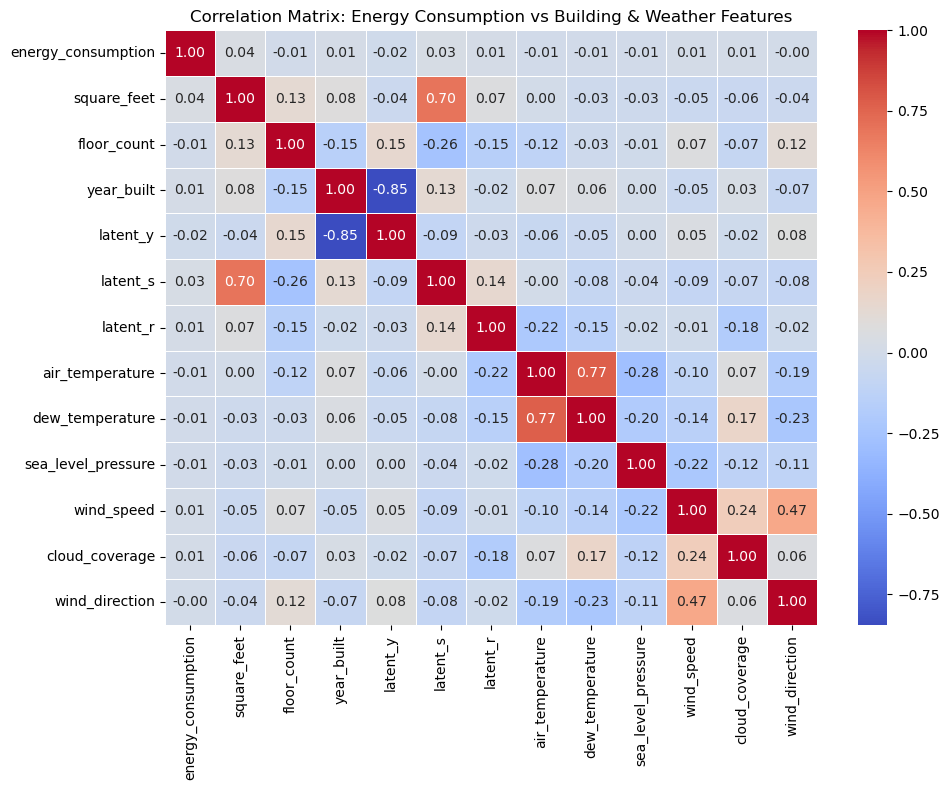

In [12]:
# ==============================
# 1.3.2 Plot 1: Correlation Heatmap of Numeric Features
# ==============================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

corr_cols = ["energy_consumption", "square_feet", "floor_count", "year_built",
             "latent_y", "latent_s", "latent_r",
             "air_temperature", "dew_temperature", "sea_level_pressure", "wind_speed",
            "cloud_coverage", "wind_direction"]

assembler = VectorAssembler(inputCols=corr_cols, outputCol="features", handleInvalid="skip")
vector_df = assembler.transform(feature_df.select(corr_cols))

# Compute the full correlation matrix directly in Spark
corr_matrix = Correlation.corr(vector_df, "features").head()[0].toArray()

# Wrap the resulting small matrix in Pandas purely for plotting
corr_pd = pd.DataFrame(corr_matrix, index=corr_cols, columns=corr_cols)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_pd, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix: Energy Consumption vs Building & Weather Features')
plt.tight_layout()
plt.show()

**Description & Discussion:**

The correlation heatmap reveals several strong relationships among the engineered and latent features, but notably weak correlations between energy_consumption and nearly all other variables (all below |0.05|). This suggests energy consumption is not linearly related to any single feature, and its right-skewed distribution (noted in earlier exploration) likely obscures linear relationships that tree-based models like Random Forest or GBT can still capture non-linearly.

Two latent columns show strong ties to known features: latent_y correlates -0.85 with year_built, and latent_s correlates 0.70 with square_feet, suggesting these are likely encoded/derived versions of those columns rather than independent information, supporting the decision to treat one of each pair as redundant. air_temperature and dew_temperature correlate 0.77, as expected physically (both track ambient warmth). wind_speed and wind_direction show a moderate 0.43 correlation, plausibly reflecting site-specific prevailing wind patterns.

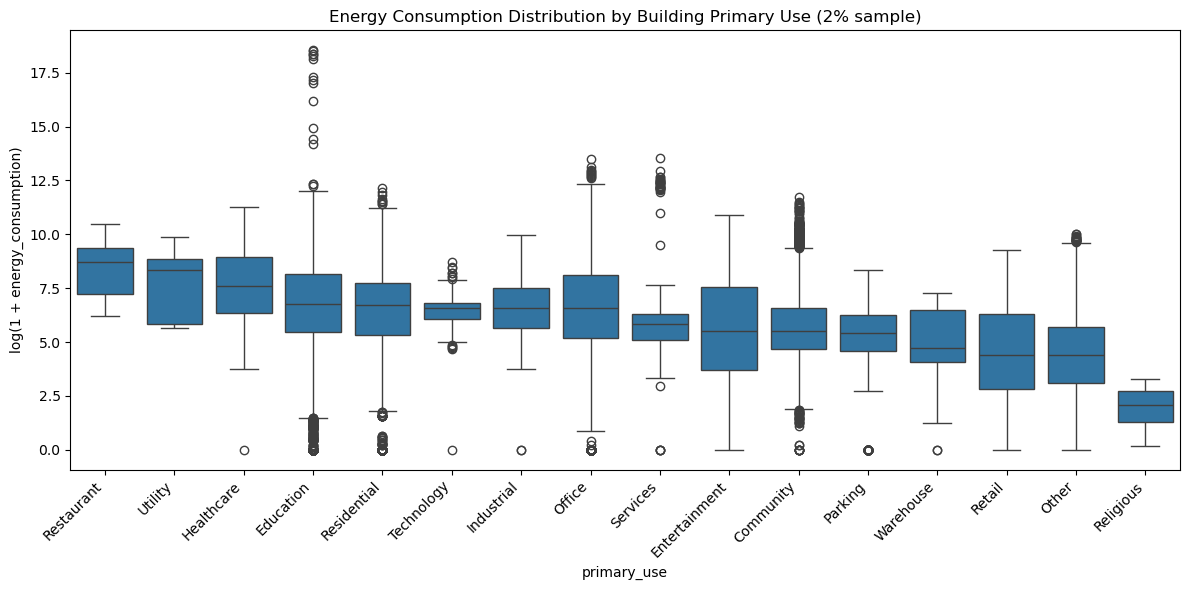

In [13]:
# ==============================
# 1.3.2 Plot 2: Boxplot of Energy Consumption by Building Primary Use
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pyspark.sql import functions as F

# Sample a small, manageable subset before pulling into Pandas.
# feature_df has 1.4M+ rows, which is too heavy for this container to
# process with per-category exact quantiles (previous attempts crashed
# the Spark JVM). A 2% sample (~28K rows) is still large enough for a
# stable distribution estimate per category.
sample_pd = feature_df.select("primary_use", "energy_consumption") \
    .sample(fraction=0.02, seed=2025) \
    .toPandas()

sample_pd["log_energy_consumption"] = np.log1p(sample_pd["energy_consumption"].astype(float))

order = sample_pd.groupby("primary_use")["log_energy_consumption"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(data=sample_pd, x="primary_use", y="log_energy_consumption", order=order)
plt.xticks(rotation=45, ha="right")
plt.ylabel("log(1 + energy_consumption)")
plt.title("Energy Consumption Distribution by Building Primary Use (2% sample)")
plt.tight_layout()
plt.show()

**Description & Discussion:**

This boxplot shows the distribution of log-transformed energy consumption across 16 building primary-use categories, using a 2% sample of feature_df. Median consumption is highest for Restaurant, Utility, and Healthcare (continuous equipment or 24-hour operations), and lowest for Religious buildings, reflecting limited, predictable usage hours.

Education and Community show a dense cluster of low outliers near zero, consistent with the meter coverage gaps identified in 1.2.1: series falling short of the full 8,760 hourly readings leave some 6-hour buckets understating consumption rather than recording genuinely low usage. Entertainment shows the widest interquartile range, along with several high outliers, likely reflecting the mix of small venues and large event spaces within that category. These patterns support including primary_use as a categorical feature, while also flagging that low-end outliers may partly reflect data quality limitations rather than true consumption behaviour.

In [9]:
# ==============================
# 1.3.3 Supplementary Check: Does Energy Consumption Differ on Weekends?
# ==============================

from pyspark.sql import functions as F

feature_df_check = feature_df.withColumn(
    "day_of_week", F.dayofweek("interval_start")  # 1=Sunday, 7=Saturday in Spark
).withColumn(
    "is_off_day", F.when(F.col("day_of_week").isin([1, 7]), 1).otherwise(0)
)

feature_df_check.groupBy("is_off_day").agg(
    F.count("*").alias("n_rows"),
    F.mean("energy_consumption").alias("mean_consumption"),
    F.expr("percentile_approx(energy_consumption, 0.5)").alias("median_consumption")
).show()

+----------+-------+----------------+------------------+
|is_off_day| n_rows|mean_consumption|median_consumption|
+----------+-------+----------------+------------------+
|         1| 408741|24000.0770469197|            492.59|
|         0|1013765|28649.3752040167|            605.71|
+----------+-------+----------------+------------------+



Median energy consumption is noticeably lower on weekends (492.59) than on weekdays (605.71) where it drops roughly 19%. This is consistent with the dataset being dominated by commercial building types (Education, Office, Entertainment), which see reduced occupancy and activity outside the working week. This pattern is not captured by any existing column, motivating the is_off_day feature introduced in Part 2.1.

## Part 2. Feature extraction and ML training <a class="anchor" name="part-2"></a>
In this section, you must use PySpark DataFrame functions and ML packages for data preparation, model building, and evaluation. Other ML packages, such as scikit-learn, should not be used to process the data; however, it’s fine to use them to display the result or evaluate your model.  
### 2.1 Discuss the feature selection and prepare the feature columns

2.1.1 Based on the data exploration from 1.2 and considering the use case, discuss the importance of those features (For example, which features may be useless and should be removed, which feature has a significant impact on the label column, which should be transformed), which features you are planning to use? Discuss the reasons for selecting them and how you plan to create/transform them.  
○	300 words max for the discussion  
○	Please only use the provided data for model building  
○	You can create/add additional features based on the dataset  
○	Hint - Use the insights from the data exploration/domain knowledge/statistical models to consider whether to create more feature columns, whether to remove some columns  

#### 2.1.1 Feature Selection Discussion

Our exploration in 1.2 and 1.3 showed every feature correlating weakly with `energy_consumption` (|r| < 0.05). That does not make them useless: RF and GBT exploit non-linear relationships Pearson correlation cannot show. Our decisions:

**Features to remove:**
- `row_id`, `site_id`, `building_id`: identifiers with no predictive value.
- `meter_type`: not in `feature_df`,consumed during 1.2.1, when the four meter types (e/c/s/h) were summed into `energy_consumption`.
- `wind_direction`: circular (0-360°), so a 6-hour average is misleading (e.g. 10° and 350° average to 180°). Correlation with the target is also ~zero (-0.00).

**Features to keep as-is:**
- `square_feet`, `floor_count`, `year_built`, `air_temperature`, `dew_temperature`, `sea_level_pressure`, `wind_speed`, `cloud_coverage`, `latent_r`: weak linear correlation, but usable for tree splits.
- `latent_y`, `latent_s`: correlate -0.85 with `year_built` and 0.70 with `square_feet`. Tree-based models are robust to multicollinearity in predictive performance, so both are retained.

**Features to keep and encode:**
- `primary_use`: 1.3.2's boxplot showed medians varying clearly by use type (Restaurant/Utility/Healthcare high, Religious low).
- `season`: peak/off-peak captures heating/cooling demand at a coarse granularity.
- Both encoded via StringIndexer and OneHotEncoder.

**Features to create:**
- `interval_period`: the label is aggregated into four 6-hour blocks, so four rows per building per day carry different loads. Without a block marker, the model sees near-identical inputs. Derived from `interval_start`, encoded as a category.
- `is_off_day`: derived from `interval_start`'s day of week (0/1). A supplementary check (1.3.3) confirms this pattern in the data: median consumption drops from 605.71 on weekdays to 492.59 on weekends (~19% lower), a pattern no existing column captures.

**Target transformation:**
- `energy_consumption` is extremely right-skewed (mean 27,313, median 574, max 125M), so log1p-transformed for training, consistent with RMSLE in 2.3.


#### 2.1.2 Write code to create/transform the columns based on your discussion above.

In [10]:
# ==============================
# 2.1.2 Create/Transform Columns Based on the 2.1.1 Discussion
# ==============================
from pyspark.sql import functions as F

# Start from the cleaned feature_df
model_df = feature_df

# Drop columns not used as model features (per 2.1.1)
# row_id, site_id, building_id, wind_direction
model_df = model_df.drop("row_id", "site_id", "building_id", "wind_direction")

# Create interval_period: which 6-hour block this row belongs to
model_df = model_df.withColumn(
    "interval_period",
    F.when(F.hour("interval_start") < 6, "00-05")
     .when(F.hour("interval_start") < 12, "06-11")
     .when(F.hour("interval_start") < 18, "12-17")
     .otherwise("18-23")
)

# Create is_off_day: weekend flag (0/1)
# F.dayofweek: 1=Sunday, 7=Saturday
model_df = model_df.withColumn(
    "day_of_week", F.dayofweek("interval_start")
).withColumn(
    "is_off_day", F.when(F.col("day_of_week").isin([1, 7]), 1).otherwise(0)
).drop("day_of_week")

# Target transformation: log1p
model_df = model_df.withColumn(
    "log_energy_consumption", F.log1p(F.col("energy_consumption").cast("double"))
)

# Verify the transformed dataframe
print("model_df schema after 2.1.2 transformations:")
model_df.printSchema()

print("Sample rows:")
model_df.select(
    "interval_start", "primary_use", "season", "interval_period",
    "is_off_day", "energy_consumption", "log_energy_consumption"
).show(5, truncate=False)

model_df schema after 2.1.2 transformations:
root
 |-- interval_start: timestamp (nullable = false)
 |-- energy_consumption: decimal(24,6) (nullable = true)
 |-- primary_use: string (nullable = true)
 |-- square_feet: integer (nullable = true)
 |-- floor_count: integer (nullable = true)
 |-- year_built: integer (nullable = true)
 |-- latent_y: decimal(10,4) (nullable = true)
 |-- latent_s: decimal(10,4) (nullable = true)
 |-- latent_r: decimal(10,4) (nullable = true)
 |-- season: string (nullable = true)
 |-- air_temperature: double (nullable = true)
 |-- dew_temperature: double (nullable = true)
 |-- sea_level_pressure: double (nullable = true)
 |-- wind_speed: double (nullable = true)
 |-- cloud_coverage: double (nullable = true)
 |-- interval_period: string (nullable = false)
 |-- is_off_day: integer (nullable = false)
 |-- log_energy_consumption: double (nullable = true)

Sample rows:
+-------------------+-----------+--------+---------------+----------+------------------+----------

### 2.2 Preparing Spark ML Transformers/Estimators for features, labels, and models  <a class="anchor" name="2.2"></a>

**2.2.1 Write code to create Transformers/Estimators for transforming/assembling the columns you selected above in 2.1 and create ML model Estimators for Random Forest (RF) and Gradient-boosted tree (GBT) model.
Please DO NOT fit/transform the data yet.**

In [11]:
# ==============================
# 2.2.1 Preparing Spark ML Transformers/Estimators
# ==============================
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import RandomForestRegressor, GBTRegressor

# Categorical columns to encode (per 2.1.1 discussion)
categorical_cols = ["primary_use", "season", "interval_period"]
indexed_cols = [f"{c}_idx" for c in categorical_cols]
encoded_cols = [f"{c}_ohe" for c in categorical_cols]

# StringIndexer: convert category strings to numeric indices.
# handleInvalid="keep" reserves an index for any category unseen at fit time
categorical_indexer = StringIndexer(
    inputCols=categorical_cols, outputCols=indexed_cols, handleInvalid="keep"
)

# OneHotEncoder: convert the indices into one-hot vectors
categorical_encoder = OneHotEncoder(inputCols=indexed_cols, outputCols=encoded_cols)

# Numeric columns used directly as features (per 2.1.1 discussion)
numeric_feature_cols = [
    "square_feet", "floor_count", "year_built",
    "latent_y", "latent_s", "latent_r",
    "air_temperature", "dew_temperature", "sea_level_pressure",
    "wind_speed", "cloud_coverage", "is_off_day"
]

# VectorAssembler: combine numeric + one-hot encoded columns into a single
# "features" vector, as required by Spark ML estimators
assembler = VectorAssembler(
    inputCols=numeric_feature_cols + encoded_cols, outputCol="features"
)

# Model estimators, trained on log_energy_consumption (per 2.1.1 target transform)
rf = RandomForestRegressor(featuresCol="features", labelCol="log_energy_consumption", seed=2025)
gbt = GBTRegressor(featuresCol="features", labelCol="log_energy_consumption", seed=2025)

print("Transformers and estimators created:")
print("- categorical_indexer, categorical_encoder, assembler")
print("- rf (RandomForestRegressor), gbt (GBTRegressor)")

Transformers and estimators created:
- categorical_indexer, categorical_encoder, assembler
- rf (RandomForestRegressor), gbt (GBTRegressor)


**2.2.2. Write code to include the above Transformers/Estimators into two pipelines.
Please DO NOT fit/transform the data yet.**

In [12]:
# ==============================
# 2.2.2 Assemble Transformers/Estimators into Two Pipelines
# ==============================
from pyspark.ml import Pipeline

# Two full pipelines: shared preprocessing stages, different model estimator.
rf_pipeline = Pipeline(stages=[categorical_indexer, categorical_encoder, assembler, rf])
gbt_pipeline = Pipeline(stages=[categorical_indexer, categorical_encoder, assembler, gbt])

print("RF pipeline stages:", [type(s).__name__ for s in rf_pipeline.getStages()])
print("GBT pipeline stages:", [type(s).__name__ for s in gbt_pipeline.getStages()])

RF pipeline stages: ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'RandomForestRegressor']
GBT pipeline stages: ['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'GBTRegressor']


In [13]:
# Checkpoint
# Writing it to disk once and reading it back gives every later action
# (sampling, splitting, model fitting) a short, cheap starting point.
model_df.write.mode("overwrite").parquet("checkpoint/model_df")
model_df = spark.read.parquet("checkpoint/model_df")
print("Checkpointed. Rows:", model_df.count())

Checkpointed. Rows: 1422506


### 2.3 Preparing the training data and testing data  
Write code to split the data for training and testing, using 2025 as the random seed. You can decide the train/test split ratio based on the resources available on your laptop.  

**Note:**
- Due to the large dataset size, you can use random sampling (say 20% of the dataset).
- `train_df`/`test_df` are cached with `.persist()` right after the split, because both are
  reused ~4x below (RF fit, GBT fit, `TrainValidationSplit`, `CrossValidator`). Without
  `persist()`, Spark would recompute the full load -> aggregate -> impute -> join -> split
  lineage from scratch on every single one of those calls. *(Ref: Damji, Wenig, Das & Lee,
  "Learning Spark," 2nd ed. (O'Reilly), Chapter 10 "Designing Machine Learning Pipelines,"
  p.292: "you should cache the training data set because you will be accessing it many
  times throughout the machine learning process.")*

In [14]:
# ==============================
# 2.3 Preparing Training and Testing Data
# ==============================
# Sample 20% of the data to keep training time manageable on a local machine
sample_fraction = 0.2
sampled_df = model_df.sample(fraction=sample_fraction, seed=2025)

print("Full cleaned dataset rows:", model_df.count())
print(f"Sampled dataset rows ({sample_fraction*100:.0f}%):", sampled_df.count())

# Split into training (80%) and testing (20%) sets, using 2025 as the seed
train_df, test_df = sampled_df.randomSplit([0.8, 0.2], seed=2025)

# Cache train/test sets
train_df = train_df.persist()
test_df = test_df.persist()

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Full cleaned dataset rows: 1422506
Sampled dataset rows (20%): 283586
Training rows: 226717
Testing rows: 56869


### 2.4 Training and evaluating models  
2.4.1 Write code to use the corresponding ML Pipelines to train the models on the training data from 2.3. And then use the trained models to predict the testing data from 2.3

In [15]:
# ==============================
# 2.4.1 Train Models on Training Data, Predict on Testing Data
# ==============================
import time

# --- Train Random Forest pipeline on train_df ---
print("Training RF pipeline...")
start = time.time()
rf_model = rf_pipeline.fit(train_df)
print(f"RF trained in {time.time() - start:.1f}s")

# Predict on test_df using the trained RF model
rf_predictions = rf_model.transform(test_df)
print("RF predictions (sample):")
rf_predictions.select("log_energy_consumption", "prediction").show(5)

# --- Train GBT pipeline on train_df ---
print("\nTraining GBT pipeline...")
start = time.time()
gbt_model = gbt_pipeline.fit(train_df)
print(f"GBT trained in {time.time() - start:.1f}s")

# Predict on test_df using the trained GBT model
gbt_predictions = gbt_model.transform(test_df)
print("GBT predictions (sample):")
gbt_predictions.select("log_energy_consumption", "prediction").show(5)

Training RF pipeline...
RF trained in 7.6s
RF predictions (sample):
+----------------------+------------------+
|log_energy_consumption|        prediction|
+----------------------+------------------+
|     4.556609995372714| 5.530711799651207|
|     8.398632603544465| 5.670778505503542|
|     4.832305758571839| 6.249544348262345|
|     9.034634880674233|7.9044306869265215|
|    3.2976870052924907| 4.461919104629107|
+----------------------+------------------+
only showing top 5 rows

Training GBT pipeline...
GBT trained in 16.3s
GBT predictions (sample):
+----------------------+------------------+
|log_energy_consumption|        prediction|
+----------------------+------------------+
|     4.556609995372714| 5.297702985271552|
|     8.398632603544465| 5.568133209202373|
|     4.832305758571839| 5.255239210933637|
|     9.034634880674233| 7.707191992595346|
|    3.2976870052924907|3.9659323067782926|
+----------------------+------------------+
only showing top 5 rows


2.4.2 For both models (RF and GBT): with the test data, decide on which metrics to use for model evaluation and discuss which one is the better model (no word limit; please keep it concise). You may also use a plot for visualisation (not mandatory).

In [16]:
# ==============================
# 2.4.2 Evaluate Models: RMSLE
# ==============================
from pyspark.sql import functions as F

# RMSLE is not a built-in metric in Spark's RegressionEvaluator, so we implement it manually
def compute_rmsle(df, actual_col, predicted_col):
    squared_log_error = F.pow(F.log1p(F.col(predicted_col)) - F.log1p(F.col(actual_col)), 2)
    mse_log = df.select(F.avg(squared_log_error)).first()[0]
    return mse_log ** 0.5

# Convert predictions back to original scale; clip negatives to 0
rf_predictions_raw = rf_predictions.withColumn(
    "predicted_energy", F.greatest(F.expm1(F.col("prediction")), F.lit(0.0))
)
gbt_predictions_raw = gbt_predictions.withColumn(
    "predicted_energy", F.greatest(F.expm1(F.col("prediction")), F.lit(0.0))
)

rf_rmsle = compute_rmsle(rf_predictions_raw, "energy_consumption", "predicted_energy")
gbt_rmsle = compute_rmsle(gbt_predictions_raw, "energy_consumption", "predicted_energy")

results = {"RF": rf_rmsle, "GBT": gbt_rmsle}

print(f"{'Model':6s}{'RMSLE':>15s}")
print("-" * 21)
for name, rmsle in results.items():
    print(f"{name:6s}{rmsle:15,.4f}")

better = "RF" if rf_rmsle < gbt_rmsle else "GBT"
print()
print(f"{better} performs better on RMSLE, the metric required by the specification.")

Model           RMSLE
---------------------
RF             1.6673
GBT            1.4987

GBT performs better on RMSLE, the metric required by the specification.


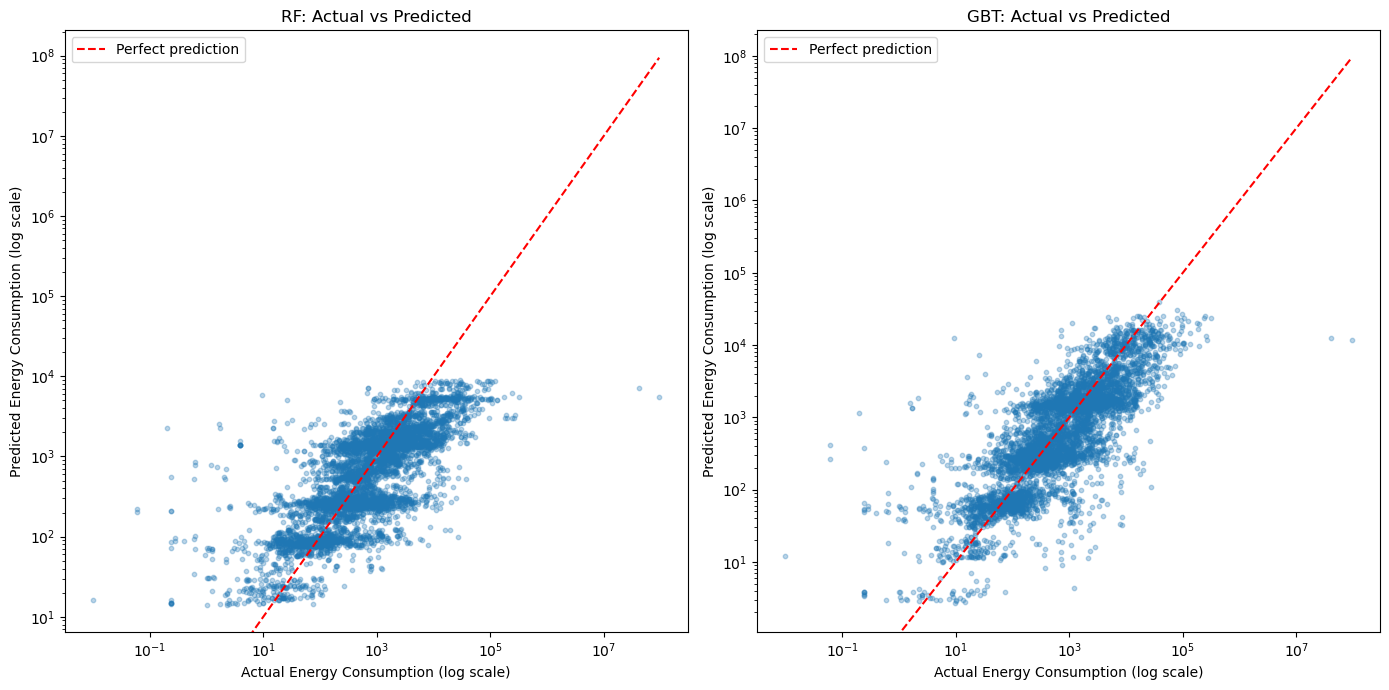

In [17]:
# ==============================
# 2.4.2 Plot: Actual vs Predicted Energy Consumption (RF and GBT)
# ==============================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, predictions_raw, model_name in [
    (axes[0], rf_predictions_raw, "RF"),
    (axes[1], gbt_predictions_raw, "GBT"),
]:
    plot_sample_pd = predictions_raw.select(
        "energy_consumption", "predicted_energy"
    ).sample(fraction=0.1, seed=2025).toPandas()

    ax.scatter(plot_sample_pd["energy_consumption"], plot_sample_pd["predicted_energy"],
               alpha=0.3, s=10)

    max_val = max(plot_sample_pd["energy_consumption"].max(),
                  plot_sample_pd["predicted_energy"].max())
    ax.plot([0, max_val], [0, max_val], color="red", linestyle="--", label="Perfect prediction")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Actual Energy Consumption (log scale)")
    ax.set_ylabel("Predicted Energy Consumption (log scale)")
    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.legend()

plt.tight_layout()
plt.show()

**Description & Discussion:**

Which metrics, and which model is better. The specification requires RMSLE, so that is 
the metric used to select the better model.

RMSLE compares `log(p+1)` against `log(a+1)`, which is the same as comparing the ratio 
`(p+1)/(a+1)`, so it measures *proportional* error. That matters here because the label spans 
several orders of magnitude: the statistics in 1.3.1 show a mean of about 27,313 against a 
median of 574 and a maximum above 125 million. An unnormalised measure would score a 100 kWh 
miss on the smallest building the same as on the largest, though the first is a total failure 
and the second a rounding error.

The Results shows **GBT scores a lower RMSLE than RF (1.4987 vs 1.6673), so GBT 
is the better model on the metric the specification requires.**

The scatter plot above is on log axes for the same reason the metric is logarithmic: on 
linear axes the largest buildings would compress every other point into the bottom-left 
corner.

2.4.3 3.	Save the better model (you’ll need it for A2B).
(Note: You may need to go through a few training loops or use more data to create a better-performing model.)

In [18]:
# ==============================
# 2.4.3 Save the Better Model for Assignment 2B
# ==============================

# Save whichever model scored the lower RMSLE in 2.4.2. The winner is read from the
# variables rather than hardcoded, so this stays correct on any re-run.
best_model = gbt_model if gbt_rmsle < rf_rmsle else rf_model
best_name  = "GBT" if gbt_rmsle < rf_rmsle else "RF"
model_save_path = "models/best_model"

best_model.write().overwrite().save(model_save_path)

print(f"Saved '{best_name}' pipeline (RMSLE={min(gbt_rmsle, rf_rmsle):.4f}) to: {model_save_path}")

from pyspark.ml import PipelineModel
loaded_model = PipelineModel.load(model_save_path)
print("Model successfully reloaded. Stages:", [type(stage).__name__ for stage in loaded_model.stages])


Saved 'GBT' pipeline (RMSLE=1.4987) to: models/best_model
Model successfully reloaded. Stages: ['StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'GBTRegressionModel']


### Part 3. Hyperparameter Tuning and Model Optimisation <a class="anchor" name="part-3"></a>  
Apply the techniques you have learnt from the labs, for example, CrossValidator, TrainValidationSplit, ParamGridBuilder, etc., to perform further hyperparameter tuning and model optimisation.  
The assessment is based on the quality of your work/process, not the quality of your model. Please include your thoughts/ideas/discussions.

In [19]:
# ==============================
# Part 3: Hyperparameter Tuning and Model Optimisation
# ==============================
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit, CrossValidator
from pyspark.ml.evaluation import RegressionEvaluator

# RMSE on log-scale prediction/label is mathematically equivalent to RMSLE
evaluator = RegressionEvaluator(
    labelCol="log_energy_consumption", predictionCol="prediction", metricName="rmse"
)

# Grid centred on maxDepth=8 / maxIter=50, a combination found to perform well
# in separate team exploration, alongside one lower-cost neighbour for comparison.
# Kept small (2x2=4 combinations) to stay within local resource limits.
param_grid = ParamGridBuilder() \
    .addGrid(gbt.maxDepth, [5, 8]) \
    .addGrid(gbt.maxIter, [20, 50]) \
    .build()

# --- Tuning with TrainValidationSplit (1 train per combination: 4 total) ---
tvs = TrainValidationSplit(
    estimator=gbt_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    trainRatio=0.8,
    seed=2025
)
tvs_model = tvs.fit(train_df)
tvs_predictions = tvs_model.transform(test_df)
tvs_rmsle = evaluator.evaluate(tvs_predictions)
tvs_best = tvs_model.bestModel.stages[-1]
print(f"TrainValidationSplit tuned GBT RMSLE: {tvs_rmsle:.4f}")
print("Best maxDepth:", tvs_best.getMaxDepth())
print("Best maxIter:", tvs_best.getMaxIter())

# --- Tuning with CrossValidator (2-fold: 4 combinations x 2 folds = 8 total) ---
cv = CrossValidator(
    estimator=gbt_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    numFolds=2,
    seed=2025
)
cv_model = cv.fit(train_df)
cv_predictions = cv_model.transform(test_df)
cv_rmsle = evaluator.evaluate(cv_predictions)
cv_best = cv_model.bestModel.stages[-1]
print(f"CrossValidator tuned GBT RMSLE: {cv_rmsle:.4f}")
print("Best maxDepth:", cv_best.getMaxDepth())
print("Best maxIter:", cv_best.getMaxIter())

# --- Compare all results ---
baseline_rmsle = evaluator.evaluate(gbt_predictions)
print("=== Summary ===")
print(f"Original GBT (Part 2, default params):  RMSLE = {baseline_rmsle:.4f}")
print(f"Tuned GBT (TrainValidationSplit):        RMSLE = {tvs_rmsle:.4f}")
print(f"Tuned GBT (CrossValidator, 2-fold):      RMSLE = {cv_rmsle:.4f}")

# --- Persist the tuned model, but only if it actually beats the Part 2 model ---
best_tuned_rmsle = min(tvs_rmsle, cv_rmsle)
best_tuned_model = tvs_model.bestModel if tvs_rmsle <= cv_rmsle else cv_model.bestModel

if best_tuned_rmsle < baseline_rmsle:
    best_tuned_model.write().overwrite().save(model_save_path)
    print(f"Tuned model wins ({best_tuned_rmsle:.4f} < {baseline_rmsle:.4f}), saved.")
else:
    print(f"Tuned model does not beat Part 2 ({best_tuned_rmsle:.4f} >= {baseline_rmsle:.4f}), unchanged.")

from pyspark.ml import PipelineModel
final_model = PipelineModel.load(model_save_path)
print("Final artifact reloads. Stages:", [type(s).__name__ for s in final_model.stages])

TrainValidationSplit tuned GBT RMSLE: 1.0798
Best maxDepth: 8
Best maxIter: 50
CrossValidator tuned GBT RMSLE: 1.0798
Best maxDepth: 8
Best maxIter: 50
=== Summary ===
Original GBT (Part 2, default params):  RMSLE = 1.4987
Tuned GBT (TrainValidationSplit):        RMSLE = 1.0798
Tuned GBT (CrossValidator, 2-fold):      RMSLE = 1.0798
Tuned model wins (1.0798 < 1.4987), saved.
Final artifact reloads. Stages: ['StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'GBTRegressionModel']


**Description & Discussion:**

Both `TrainValidationSplit` and `CrossValidator` independently selected the same best combination (`maxDepth=8`, `maxIter=50`), with identical final RMSLE (1.0798). This agreement is itself worth noting: the two methods search very differently.
1. TVS evaluates each combination once on a single 80/20 internal split
2. CrossValidator (2-fold) evaluates each combination twice, on two different halves of the data, and averages the result. CrossValidator is generally considered more robust, since it is less sensitive to how one particular split happens to divide the data.

That both methods still converge on the same combination here suggests the training set is large enough that this variance barely matters in practice. The extra computation CrossValidator requires (roughly double the training runs) provided little additional insight for this dataset, though it does add confidence: the result likely reflects a genuinely good parameter combination rather than one that happened to suit a single split.

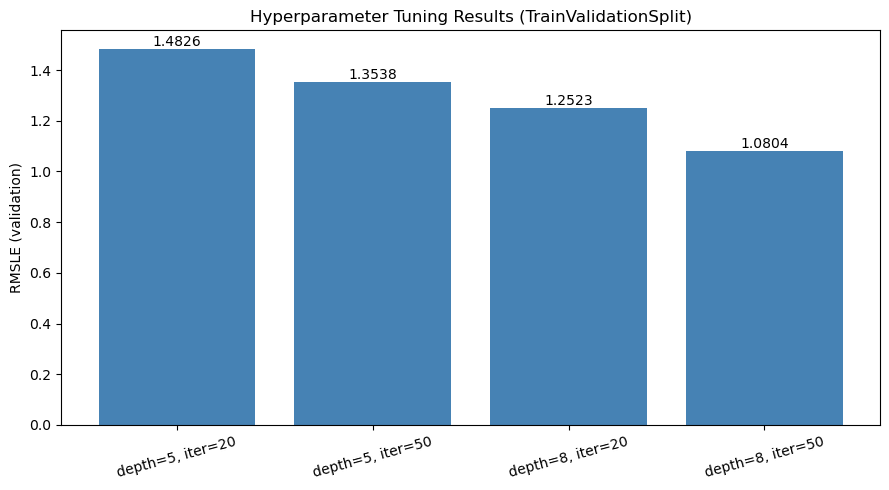

In [20]:
# Visualize RMSLE across the 4 hyperparameter combinations tried
import matplotlib.pyplot as plt

combo_labels = [f"depth={p[gbt.maxDepth]}, iter={p[gbt.maxIter]}" for p in param_grid]
scores = tvs_model.validationMetrics

plt.figure(figsize=(9, 5))
bars = plt.bar(combo_labels, scores, color='steelblue')

# Add the RMSLE value on top of each bar
for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{score:.4f}",
        ha='center', va='bottom'
    )

plt.ylabel("RMSLE (validation)")
plt.title("Hyperparameter Tuning Results (TrainValidationSplit)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Description & Discussion

**Tuning setup.** We tuned the GBT model (the Part 2 winner) with ParamGridBuilder over two hyperparameters, maxDepth ([5, 8]) and maxIter ([20, 50]), giving four combinations. The ranges start at Spark's defaults for GBTRegressor and extend past them, so the search can test whether extra depth or more boosting rounds help rather than only confirming the default setting. The evaluator minimises RMSE on the log1p-transformed label, which is RMSLE on the original scale, so tuning optimises the same metric the spec requires.

**Why two search strategies.** TrainValidationSplit fits each combination once against a single 80/20 validation slice, while CrossValidator with 2 folds fits each combination twice and averages. Running both lets us check whether the cheaper single-split search reaches the same conclusion as the more thorough one, at a fraction of the cost.

**Persisting the result.** The tuned model overwrites models/best_model only if it actually scores better than the Part 2 model on the same evaluator, so a tuning run that fails to improve leaves the existing model untouched.

**Results and impact.** Both searches selected maxDepth=8 with maxIter=50 and scored RMSLE 1.0798, against 1.4987 for the Part 2 default model, an improvement of roughly 28%. That the single-split and 2-fold searches agreed on the same combination suggests the ranking is stable rather than an artefact of one validation split.

**Reading the validation scores.** Both searches chose the largest value of both parameters, which means the grid's optimum sits on its boundary, which indicates that the best configuration may lie outside the range tested. The validation scores plotted above show why: RMSLE fell at every step, from 1.4826 at Spark's defaults to 1.3538 with more boosting rounds, 1.2523 with deeper trees, and 1.0804 with both. The largest single gain, 0.2734, came from increasing depth at the higher iteration count, so the search was still improving when it stopped rather than flattening out. Depth was consistently the more productive axis, gaining 0.2303 and 0.2734 against 0.1288 and 0.1719 for extra iterations, which is where a wider sweep should start. The tuned model achieved an RMSLE of 1.0804 during validation and 1.0798 on the held-out test set, showing very similar predictive performance across the two evaluations. This suggests that the selected configuration generalises well to the available held-out data. The honest conclusion is that deeper trees were still paying off when we stopped: maxDepth=8 with maxIter=50 is the best setting found within the compute available, not the best that exists.

**Scope of the grid.** Four combinations already means 4 fits for TrainValidationSplit plus 8 for 2-fold CrossValidator, and this was deliberately kept small given limited local compute. A wider sweep (maxDepth to 12+, maxIter to 100+, plus stepSize and subsamplingRate) would be the natural next step given more compute, and the assessment here is on the tuning process rather than the last fraction of accuracy.

**Model complexity and generalisation.** The selected maxDepth=8 and maxIter=50 provide a balance between model flexibility and computational cost. Increasing tree complexity can reduce training error while increasing the risk of fitting noise rather than patterns that generalise to unseen data. Although the supplementary depth experiment was not retained due to computational constraints, the agreement between TrainValidationSplit and CrossValidator on the same hyperparameter combination provides additional support for the selected configuration. Therefore, the final model was selected based on validation performance rather than training performance alone.

## Part 4. Data ethics, privacy, and security

*Topic chosen: data privacy.*

As more of daily life is metered and logged, ethical, privacy, and security questions grow with it. Data ethics asks whether a use of data is defensible, not only whether it is lawful. Data privacy concerns the control people keep over information about them. Data security concerns the technical and organisational measures that stop that information being read or altered without authorisation. The three come apart: a pipeline can be secure and still be unethical, or lawful and still expose people. Smart metering shows why this matters now, because the readings that let a utility plan capacity also describe when a household is at home.

Both UU PDP (Law 27 of 2022) and the GDPR set a 72-hour breach clock, but they differ on who must be told. GDPR Article 33 applies that clock to the supervisory authority, while Article 34 requires informing data subjects only where the breach is likely to be high risk, with no fixed deadline. UU PDP Article 46 places the customer on the same 3x24-hour clock as the regulator regardless of risk, and adds public notification where a breach disturbs public services. Both conditions bind an Indonesian utility: it cannot triage first and tell customers afterwards, and an incident affecting supply meets the public-notice threshold. Enforcement is still maturing, since the PDP Agency the law provides for has not yet been established.

Meter data reveals more than its column names suggest. At fine resolution it exposes occupancy and even individual appliance use (Molina-Markham et al., 2010). The 6-hour aggregation in 1.2.1 was specified to cut data volume, yet four readings a day support far weaker reconstruction than twenty-four. The larger residual risk is the building metadata: square_feet, year_built and primary_use act as quasi-identifiers, and the largest building here is almost certainly unique within its site, so removing names does not anonymise it (Sweeney, 2002). 

Such objections have already reshaped real deployments. The Dutch Senate blocked two smart metering bills in 2009 after a study concluded mandatory installation would breach Article 8 ECHR (Cuijpers and Koops, 2012).

Controls follow directly: keep the coarsest resolution the forecast tolerates, treat metadata as identifying and apply k-anonymity before any release, add calibrated noise to published aggregates, encrypt data, restrict raw access by role, and set retention limits. None of these are free of trade-offs: k-anonymity alone can fail against background-knowledge attacks and needs pairing with noise, and added noise trades against the forecast accuracy Part 2's model was built for. Two approaches go further. Differential privacy replaces a judgement call with a measurable bound on disclosure, and federated learning trains across sites without centralising raw readings, an active research direction for grid data (Zhang et al., 2025).

In summary, the strongest privacy protection in this pipeline is an aggregation step adopted for engineering reasons; the residual risk sits in the building metadata rather than the readings; and UU PDP obliges an Indonesian operator to notify customers on a fixed clock that GDPR would leave conditional.

## References


Apache Software Foundation. *pyspark.ml.feature.Imputer*, Spark Python API documentation. https://spark.apache.org/docs/3.5.5/api/python/reference/api/pyspark.ml.feature.Imputer.html (used for the imputation in 1.2.2).

Cuijpers, C. and Koops, B.-J. (2012). Smart metering and privacy in Europe: lessons from the Dutch case. In: Gutwirth, S., Leenes, R., de Hert, P. and Poullet, Y. (eds), *European Data Protection: Coming of Age*. Springer, pp. 269-293.

Damji, J.S., Wenig, B., Das, T. and Lee, D. (2020). *Learning Spark: Lightning-Fast Data Analytics*, 2nd edition. O'Reilly Media. Chapter 10, p. 292 (cited in 2.3 on caching the training data).

European Parliament and Council of the European Union (2016). *Regulation (EU) 2016/679 (General Data Protection Regulation)*, Articles 33 and 34.

Molina-Markham, A., Shenoy, P., Fu, K., Cecchet, E. and Irwin, D. (2010). Private memoirs of a smart meter. *Proceedings of the 2nd ACM Workshop on Embedded Sensing Systems for Energy-Efficiency in Buildings (BuildSys '10)*, pp. 61-66.

Republic of Indonesia (2022). *Undang-Undang Nomor 27 Tahun 2022 tentang Pelindungan Data Pribadi (UU PDP)*, Article 46.

Sweeney, L. (2002). k-anonymity: a model for protecting privacy. *International Journal of Uncertainty, Fuzziness and Knowledge-Based Systems*, 10(5), pp. 557-570.

Taniar, D., Leung, C.H.C., Rahayu, W. and Goel, S. (2008). *High-Performance Parallel Database Processing and Grid Databases*. John Wiley & Sons. Section 2.3, p. 39 (cited in 1.1.1 on partitioning and workload skew).

Zhang, Z., Rath, S., Xu, J. and Xiao, T. (2025). Federated learning for smart grid: a survey on applications and potential vulnerabilities. *ACM Transactions on Cyber-Physical Systems*. arXiv:2409.10764.

### Generative AI use

Generative AI (Claude, Anthropic) was used during this assignment in three ways:

- **Debugging.** Diagnosing PySpark errors and runtime failures, including a schema type mismatch that silently nulled two weather columns, and configuration problems in the Docker environment.
- **Locating literature.** Finding and verifying the published sources cited above, in particular the regulatory and 
privacy sources used in Part 4. Author names, years and page references were checked against the original publications rather than accepted as given.
- **Re-examining working code.** Reviewing code that already ran without error, to check whether it was correct and efficient rather than merely functional. This surfaced the duplicate meter keys handled in 1.2.1 and the missing time-of-day feature added in 2.1.2.

All analysis decisions, written discussion and reported figures were reviewed by the authors and checked against the notebook's own printed output before inclusion.

Representative prompts, translated from Indonesian and grouped by the three uses above. This is a selection rather than the full log.

*Debugging*

- "Run this notebook in the Docker environment and report any errors."
- "Explain why cloud_coverage came out 100% null before."
- "Check the progress of the run and whether it is still safe."

*Locating literature*

- "Is there a requirement for which metric decides the better model?"
- "In the literature, which metrics are used for this problem?"
- "Explain what RMSLE, CV(RMSE) and NMBE are, and how our results compare with the standard."
- "Check whether these two books are used as references."

*Re-examining working code*

- "Compare A2A_template.ipynb against our other notebook, focusing on the code and the logic."
- "List where the bugs are, why they are bugs, and how to fix them."
- "Act as a data science lecturer and evaluate how well our answer matches the specification and the course material."
- "Check the EDA and cleaning against the data audit we did."
